# Chapter 7 — Support Vector Machines and Kernel Methods
**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Environment:** Google Colab / Jupyter Notebook

This notebook compares linear and nonlinear SVM kernels, visualizes decision boundaries, tunes key hyperparameters, and tests an SVM on high-dimensional data.

## 1. Theory: support vector machines

An SVM seeks a decision boundary with a large margin between classes. The observations closest to the boundary are the **support vectors**. Kernel functions allow SVMs to represent nonlinear boundaries.

- **Linear kernel:** useful when a linear boundary is adequate or the feature space is large.
- **RBF kernel:** flexible nonlinear boundary controlled in part by `gamma`.
- **Polynomial kernel:** models polynomial interactions.
- `C` controls the trade-off between margin width and training errors. Larger `C` penalizes misclassification more strongly.

SVMs are sensitive to feature scales, so scaling is included in the pipeline.

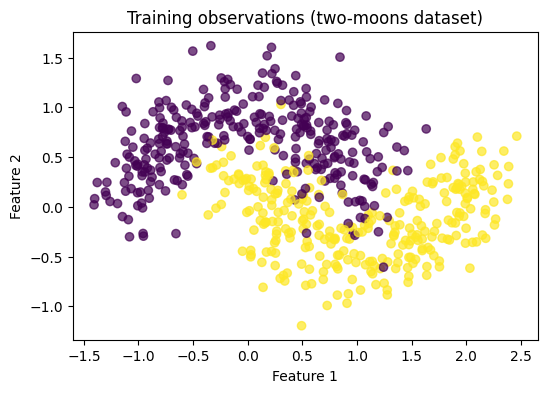

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
RANDOM_STATE = 42

X, y = make_moons(n_samples=800, noise=0.25, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
plt.figure(figsize=(6, 4))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, alpha=0.7)
plt.title("Training observations (two-moons dataset)")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()

## 2. Compare linear, polynomial, and RBF kernels

In [2]:
models = {
    "Linear": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "Polynomial": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=3, C=1.0)),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({"Kernel": name, "Test accuracy": accuracy_score(y_test, model.predict(X_test))})
display(pd.DataFrame(rows).set_index("Kernel").round(3))

,Test accuracy
Kernel,
Linear,0.895
Polynomial,0.895
RBF,0.955


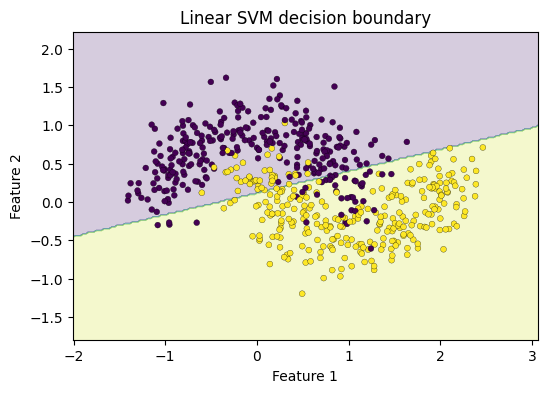

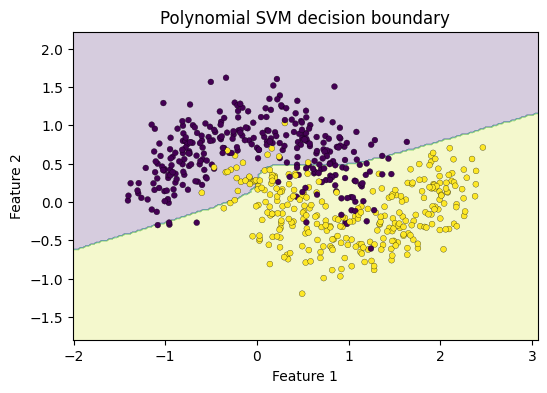

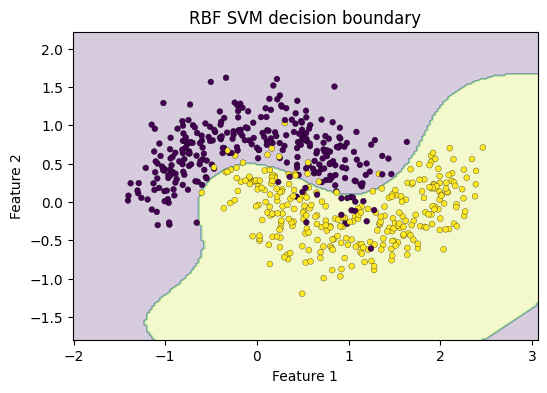

In [3]:
def plot_decision_boundary(model, X, y, title):
    model.fit(X, y)
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 180),
                         np.linspace(y_min, y_max, 180))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, zz, alpha=0.22)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=18, edgecolors="k", linewidths=0.2)
    plt.title(title); plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()

for name, model in models.items():
    plot_decision_boundary(model, X_train, y_train, f"{name} SVM decision boundary")

**Interpretation:** a linear kernel cannot naturally bend around the two-moons structure. Nonlinear kernels can fit curved boundaries, but greater flexibility can also overfit. Use validation results, not visual appearance alone, to choose a model.

## 3. Tune SVM hyperparameters with cross-validation

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Best mean CV accuracy: 0.947
Test accuracy: 0.955
              precision    recall  f1-score   support

           0       0.94      0.97      0.96       100
           1       0.97      0.94      0.95       100

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200



Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

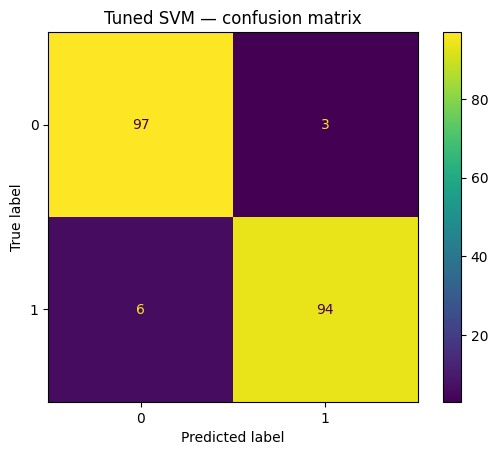

In [4]:
svm_pipe = make_pipeline(StandardScaler(), SVC())
param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100],
     "svc__gamma": ["scale", 0.1, 1.0]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10],
     "svc__degree": [2, 3], "svc__gamma": ["scale"]}
]
search = GridSearchCV(svm_pipe, param_grid, scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best mean CV accuracy: {search.best_score_:.3f}")
pred = search.best_estimator_.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}")
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.title("Tuned SVM — confusion matrix"); plt.show()

## 4. SVM with high-dimensional data

In [5]:
X_hd, y_hd = make_classification(n_samples=700, n_features=80, n_informative=12,
    n_redundant=10, class_sep=0.9, random_state=RANDOM_STATE)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_hd, y_hd, test_size=0.25, stratify=y_hd, random_state=RANDOM_STATE)
high_dim_svm = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
high_dim_svm.fit(Xh_train, yh_train)
print("High-dimensional linear SVM accuracy:",
      round(accuracy_score(yh_test, high_dim_svm.predict(Xh_test)), 3))

High-dimensional linear SVM accuracy: 0.737


## 5. Hands-on exercises

1. Change `C` from 0.1 to 100 and describe how the boundary and accuracy change.
2. For the RBF kernel, compare `gamma="scale"`, `0.1`, and `1.0`.
3. Try a noisier two-moons dataset and discuss why model selection becomes harder.
4. Explain why scaling is part of the pipeline.
5. Use PCA to project the high-dimensional dataset into two dimensions for visualization, then explain why visualization is not the same as model evaluation.

## 6. Chapter summary

- SVMs seek a large-margin decision boundary.
- Kernel choice controls the kinds of boundaries a model can learn.
- `C` and `gamma` are important tuning parameters.
- Scaling is important for SVMs.
- Cross-validation helps choose kernels and hyperparameters; the test set is reserved for final evaluation.